## Cell 1: Gradient boosting for building energy use

**Owner: Yera Smagulov**

#### Objectives
1. Train a simple gradient boosting model.
2. Try changes to model settings, input features, and target representation.
3. Compare training and validation results and discuss generalization.

#### Motivation
An acquisition analyst may know a building's characteristics but not its utility
history. We want to estimate its annual major-fuels consumption, MFBTU, in kBtu.

#### Data
Using the processed 2018 CBECS data: 23 source variables plus missing flags,
threshold handling, and optional engineered features. Keeping our project's
70/15/15 split. Final test scoring is complete; keep the results final.

## Cell 2: Import libraries

Use scikit-learn's histogram gradient boosting regressor. The CSV can be in
the repo root or `data/processed`. Results go to `results/gradient_boosting`.
Run all cells in order so the outputs are saved with the notebook.

In [1]:
# Cell 3: Imports and paths
from pathlib import Path
import hashlib
import json
import platform
import joblib
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
cwd = Path.cwd()
choices = [(root, path) for root in [cwd, cwd.parent]
           for path in [root / 'cbecs2018_processed.csv', root / 'data/processed/cbecs2018_processed.csv']]
found = next(((root, path) for root, path in choices if path.exists()), None)
if found is None:
    raise FileNotFoundError('Run preprocessing or place the updated cbecs2018_processed.csv in the project root.')
root, data_path = found
results_dir = root / 'results/gradient_boosting'
results_dir.mkdir(parents=True, exist_ok=True)
print(f'Using {data_path.name}; results go to results/gradient_boosting/.')


Using cbecs2018_processed.csv; results go to results/gradient_boosting/.


## Cell 4: Step 1: Data ingestion

Load the current processed CSV and check its shape and columns. Preview
training rows only. The updated CSV is required.

In [2]:
# Cell 5: Load and preview the data
data = pd.read_csv(data_path)
print('Data shape:', data.shape)
print('Split counts:')
print(data['split'].value_counts())
display(data.loc[data['split'].eq('train'), ['PUBID', 'SQFT', 'NWKER', 'WKHRS', 'OCCUPYP', 'MFBTU']].head())

Data shape: (6357, 186)
Split counts:
split
train         4449
validation     954
test           954
Name: count, dtype: int64


,PUBID,SQFT,NWKER,WKHRS,OCCUPYP,MFBTU
0,1,210000,350,70,100,29727152
1,2,28000,12,45,100,1730655
2,3,2100,6,48,100,52387
3,4,240000,34,55,96,3185775
4,5,295000,10,80,96,4677009


## Cell 6: Step 2: Exploratory data analysis

Most EDA is in the preprocessing notebook. Here we quickly check the training
target's range. A log-scale view helps us see small and large buildings together.
This plot doesn't change the target values.

,Training MFBTU (kBtu)
count,4.449000e+03
mean,1.586833e+07
std,3.826155e+07
min,1.600000e+02
25%,6.631920e+05
50%,4.397988e+06
75%,1.575568e+07
max,8.025880e+08


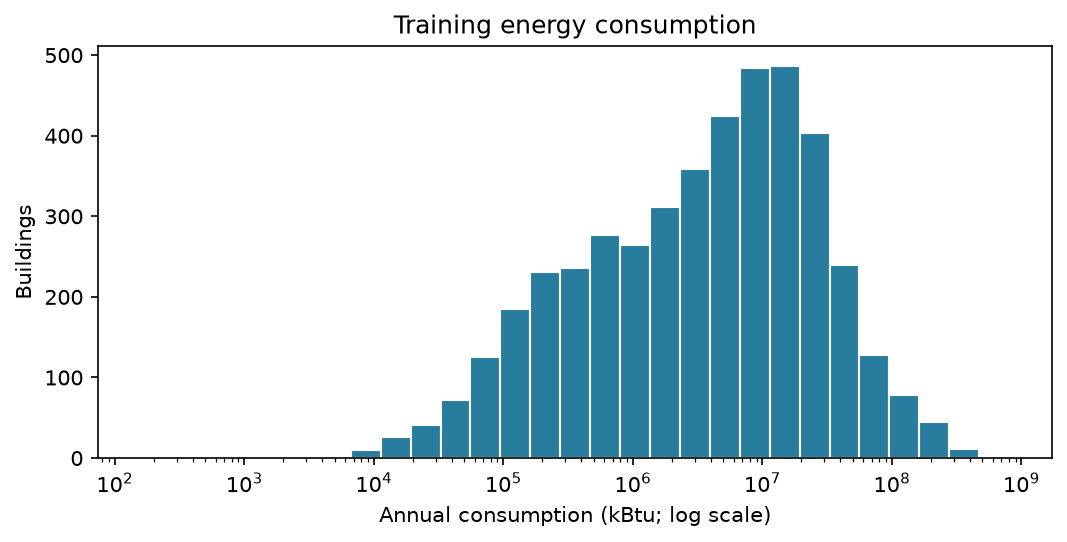

Mean: 15,868,331; median: 4,397,988; skewness: 7.69.


In [3]:
# Cell 7: Check the training target
import matplotlib.pyplot as plt
from IPython.display import Image

eda_target = data.loc[data['split'].eq('train'), 'MFBTU']
display(eda_target.describe().to_frame('Training MFBTU (kBtu)'))
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.hist(eda_target, bins=np.geomspace(eda_target.min(), eda_target.max(), 30), color='#287c9e', edgecolor='white')
ax.set_xscale('log')
ax.set(title='Training energy consumption', xlabel='Annual consumption (kBtu; log scale)', ylabel='Buildings')
target_plot = results_dir / 'training_target_distribution.png'
fig.savefig(target_plot, dpi=150, bbox_inches='tight', facecolor='white')
plt.close(fig)
display(Image(filename=str(target_plot)))
print(f'Mean: {eda_target.mean():,.0f}; median: {eda_target.median():,.0f}; skewness: {eda_target.skew():.2f}.')


## Cell 8: Comment on the distribution

A few buildings use much more energy than most. This gives us a reason to try
both the original target and log1p(MFBTU). We still compare errors in original
kBtu units, so a target transform can't make the reported scores look smaller
just by changing units.

## Cell 9: Step 3: Data preprocessing

Preprocessing is already done. So, here I'm reusing its training/validation membership and
unscaled inputs; not creating a new split. IDs and MFBTU are staying outside X.

Both variants retain all 23 source variables and their missing/cap flags.
The base variant has 175 columns; adding eight combinations gives 183.

In [4]:
# Cell 10: Prepare the two feature sets
engineered = ['log1p_SQFT', 'log1p_NWKER', 'workers_per_1000_sqft', 'weekly_floor_area_hours',
              'heated_floor_area', 'cooled_floor_area', 'heating_area_degree_days', 'cooling_area_degree_days']
source_numeric = ['SQFT', 'FLCEILHT', 'WKHRS', 'NWKER', 'MONUSE', 'HDD65', 'CDD65', 'HEATP', 'COOLP', 'OCCUPYP']
source_categorical = ['CENDIV', 'PBA', 'PUBCLIM', 'WLCNS', 'RFCNS', 'RFTILT', 'BLDSHP', 'GLSSPC',
                      'NFLOOR', 'YRCONC', 'ATTIC', 'MAINHT', 'MAINCL']
missing_flags = [col + '__is_missing' for col in source_numeric + source_categorical]
required = ['PUBID', 'split', 'MFBTU', 'SQFT__above_1m', 'NWKER__5000_or_more'] + source_numeric + missing_flags + engineered
assert set(required).issubset(data.columns), 'Wrong dataset: use the updated 23-variable processed CSV.'
assert data.PUBID.is_unique and data.PUBID.notna().all()
assert data['split'].value_counts().to_dict() == {'train': 4449, 'validation': 954, 'test': 954}
train = data.loc[data['split'].eq('train')].sort_values('PUBID').copy()
validation = data.loc[data['split'].eq('validation')].sort_values('PUBID').copy()
all_features = [col for col in data.columns if col not in ['PUBID', 'split', 'MFBTU']]
feature_sets = {'base': [col for col in all_features if col not in engineered], 'engineered': all_features}
assert len(feature_sets['base']) == 175 and len(feature_sets['engineered']) == 183
for col in source_categorical:
    assert any(c.startswith(col + '__') and c != col + '__is_missing' for c in all_features)
assert set(train.PUBID).isdisjoint(validation.PUBID)
for frame in [train, validation]:
    assert np.isfinite(frame[all_features + ['MFBTU']].to_numpy()).all()
    assert frame.MFBTU.ge(0).all()
    assert frame.SQFT.le(1_000_000).all() and frame.NWKER.le(5_000).all()
y_train, y_validation = train.MFBTU, validation.MFBTU
display(pd.DataFrame({'Training': [len(train)], 'Validation': [len(validation)],
                      'Base columns': [175], 'Engineered columns': [183]}))


,Training,Validation,Base columns,Engineered columns
0,4449,954,175,183


## Cell 11: Step 4: Modeling - baseline

Start with a small boosting model: 50 iterations and at most seven leaves per
tree, using the base inputs and original target. This is a starting point for
my boosting experiments; Jiayi's linear regression is still the team's baseline.

We report MAE, RMSE, and R-squared for training and validation. MAE is the main
selection metric. Negative energy predictions are clipped to zero in every run.

In [5]:
# Cell 12: Define model and evaluation helpers
def build_model(params, target='original'):
    """Build a reproducible gradient boosting regressor."""
    estimator = HistGradientBoostingRegressor(**params, early_stopping=False, random_state=SEED)
    if target == 'log1p':
        return TransformedTargetRegressor(regressor=estimator, func=np.log1p, inverse_func=np.expm1)
    return estimator

def predict_kbtu(estimator, values):
    """Return finite, nonnegative predictions in original kBtu units."""
    prediction = np.maximum(estimator.predict(values), 0)
    assert np.isfinite(prediction).all()
    return prediction

def metrics(actual, predicted):
    return {'MAE_kBtu': float(mean_absolute_error(actual, predicted)),
            'RMSE_kBtu': float(np.sqrt(mean_squared_error(actual, predicted))),
            'R2': float(r2_score(actual, predicted))}


In [6]:
# Cell 13: Train and evaluate the baseline
baseline_params = {'learning_rate': 0.10, 
                   'max_iter': 50, 
                   'max_leaf_nodes': 7,
                   'min_samples_leaf': 20, 
                   'l2_regularization': 1.0
                   }
baseline_model = build_model(baseline_params)
baseline_columns = feature_sets['base']
baseline_model.fit(train[baseline_columns], y_train)
baseline_train_metrics = metrics(y_train, predict_kbtu(baseline_model, train[baseline_columns]))
baseline_val_metrics = metrics(y_validation, predict_kbtu(baseline_model, validation[baseline_columns]))
baseline_table = pd.DataFrame([{'Partition': 'Training', **baseline_train_metrics},
                               {'Partition': 'Validation', **baseline_val_metrics}])
display(baseline_table.round(3))

# Constant predictions provide another quick sanity check.
baseline_rows = []
for name, value in [('Training mean', y_train.mean()), ('Training median', y_train.median())]:
    baseline_rows.append({'reference': name, **metrics(y_validation, np.full(len(validation), value))})
baselines = pd.DataFrame(baseline_rows)
display(baselines.round(3))


,Partition,MAE_kBtu,RMSE_kBtu,R2
0,Training,5560935.738,1.594361e+07,0.826
1,Validation,5478702.190,1.447224e+07,0.843


,reference,MAE_kBtu,RMSE_kBtu,R2
0,Training mean,1.782516e+07,3.649891e+07,-0.001
1,Training median,1.375467e+07,3.790603e+07,-0.080


## Cell 14: Comment on baseline performance

Training MAE is 5.56 million kBtu and validation MAE is 5.48 million kBtu. This gives us a reference for the improvement experiments below.

## Cell 15: Step 4: Modeling - improvement experiments

Try four settings with base/engineered inputs and original/log1p targets:
16 runs total. The table shows training and validation performance, like our
course experiment tables. More iterations or larger trees may improve fitting
but can also increase overfitting.

Early stopping is off to avoid a second internal validation split. We choose
by fixed-validation MAE, with RMSE breaking ties. No test scores are used.

In [7]:
# Cell 16: Run the experiment table
settings = [
    {'learning_rate': 0.05, 'max_iter': 150, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'l2_regularization': 1.0},
    {'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'l2_regularization': 1.0},
    {'learning_rate': 0.10, 'max_iter': 150, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'l2_regularization': 1.0},
    {'learning_rate': 0.05, 'max_iter': 300, 'max_leaf_nodes': 31, 'min_samples_leaf': 40, 'l2_regularization': 5.0},
]


display(pd.DataFrame(settings, index=range(1, 5)).rename_axis('Setting'))

models, trials = {}, []
for variant, columns in feature_sets.items():
    for target in ['original', 'log1p']:
        for setting_id, params in enumerate(settings, 1):
            trial_id = f'{variant}_{target}_{setting_id}'
            estimator = build_model(params, target)
            estimator.fit(train[columns], y_train)
            prediction = predict_kbtu(estimator, validation[columns])
            training_scores = metrics(y_train, predict_kbtu(estimator, train[columns]))
            models[trial_id] = estimator
            trials.append({'trial_id': trial_id, 
                           'features': variant, 
                           'target_fit': target,
                           'setting_id': setting_id, 
                           'feature_count': len(columns), 
                           **params,
                           **metrics(y_validation, prediction),
                           **{'Train_' + key: value for key, value in training_scores.items()}})
search = pd.DataFrame(trials).sort_values(['MAE_kBtu', 'RMSE_kBtu', 'trial_id']).reset_index(drop=True)
display(search[['trial_id', 'Train_MAE_kBtu', 'MAE_kBtu', 'Train_R2', 'R2']].round(3))


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization
Setting,,,,,
1,0.05,150,15,20,1.0
2,0.05,300,15,20,1.0
3,0.10,150,31,20,1.0
4,0.05,300,31,40,5.0


,trial_id,Train_MAE_kBtu,MAE_kBtu,Train_R2,R2
0,engineered_log1p_2,4492611.492,4421280.685,0.800,0.826
1,engineered_log1p_4,4047436.266,4528380.475,0.821,0.829
2,engineered_log1p_3,3760854.048,4589551.645,0.853,0.829
3,engineered_log1p_1,4924807.501,4669442.771,0.755,0.792
4,base_log1p_2,4491870.260,4686924.527,0.794,0.813
5,base_log1p_1,4898665.879,4713423.284,0.755,0.805
6,base_log1p_3,3870625.772,4746405.254,0.849,0.815
7,base_log1p_4,4074666.872,4775176.005,0.819,0.811
8,engineered_original_4,3825897.852,5010548.547,0.874,0.860
9,engineered_original_3,2823097.042,5057593.824,0.955,0.854


## Cell 17: How these runs differ from the baseline

We increase the number of boosting iterations and try more leaves, different
learning rates, larger minimum leaves, and stronger regularization. We also
test Tom's candidate feature combinations and a log fitting target. Only
validation results determine which combination we keep.

## Cell 18: Step 5: Evaluation and generalization

Compare the selected model with the baseline on both partitions. Training
error alone isn't enough: a much larger validation error can suggest overfitting.
The validation score has been used for tuning, so it isn't a final test score.

In [8]:
# Cell 19: Compare baseline and tuned results
winner = search.iloc[0]
best_model = models[winner.trial_id]
best_columns = feature_sets[winner.features]
best_prediction = predict_kbtu(best_model, validation[best_columns])
best_metrics = metrics(y_validation, best_prediction)
assert np.isclose(best_metrics['MAE_kBtu'], winner.MAE_kBtu)
best_by_variant = search.groupby(['features', 'target_fit'], sort=False).head(1)
display(best_by_variant[['features', 'target_fit', 'setting_id', 'MAE_kBtu', 'RMSE_kBtu', 'R2']].round(3))
print(f'Selected: {winner.trial_id}; validation MAE {best_metrics["MAE_kBtu"]:,.0f} kBtu.')
print('The selected estimator is fitted on training rows only.')
best_train_metrics = metrics(y_train, predict_kbtu(best_model, train[best_columns]))
comparison = pd.DataFrame([
    {'Model': 'Baseline boosting', **{'Train_' + key: value for key, value in baseline_train_metrics.items()}, **baseline_val_metrics},
    {'Model': 'Tuned boosting', **{'Train_' + key: value for key, value in best_train_metrics.items()}, **best_metrics},
])
display(comparison.round(3))
improvement_percent = 100 * (baseline_val_metrics['MAE_kBtu'] - best_metrics['MAE_kBtu']) / baseline_val_metrics['MAE_kBtu']
print(f'Validation MAE improvement over baseline boosting: {improvement_percent:.1f}%.')

,features,target_fit,setting_id,MAE_kBtu,RMSE_kBtu,R2
0,engineered,log1p,2,4421280.685,1.519802e+07,0.826
4,base,log1p,2,4686924.527,1.578265e+07,0.813
8,engineered,original,4,5010548.547,1.366833e+07,0.860
11,base,original,4,5130153.930,1.494732e+07,0.832


Selected: engineered_log1p_2; validation MAE 4,421,281 kBtu.
The selected estimator is fitted on training rows only.


,Model,Train_MAE_kBtu,Train_RMSE_kBtu,Train_R2,MAE_kBtu,RMSE_kBtu,R2
0,Baseline boosting,5560935.738,1.594361e+07,0.826,5478702.190,1.447224e+07,0.843
1,Tuned boosting,4492611.492,1.712934e+07,0.800,4421280.685,1.519802e+07,0.826


Validation MAE improvement over baseline boosting: 19.3%.


## Cell 20: Comment on training versus validation

The selected run has training MAE 4.49 million kBtu and validation MAE 4.42 million kBtu. The MAEs are close, with no large positive validation gap. This alone does not prove generalization. We choose by MAE and report final test results separately. The baseline has better validation RMSE (14.47 vs 15.20 million kBtu) and R-squared (0.843 vs 0.826). The tuned model is not better on every metric.

## Cell 21: Learning curves

Plot training and validation MAE as boosting iterations are added. Both curves
use original kBtu units. This is a diagnostic of the chosen run; it doesn't
select another setting. The model's fitting loss can differ from plotted MAE.

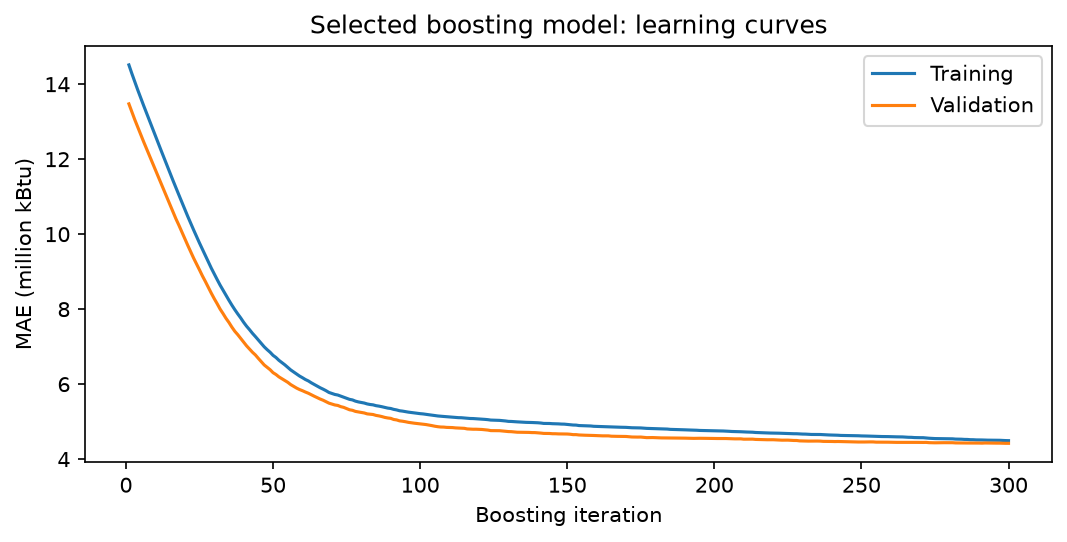

In [9]:
# Cell 22: Plot MAE across boosting iterations
tree_model = best_model.regressor_ if isinstance(best_model, TransformedTargetRegressor) else best_model
history = []
for iteration, (training_prediction, validation_prediction) in enumerate(zip(
        tree_model.staged_predict(train[best_columns]), tree_model.staged_predict(validation[best_columns])), 1):
    if winner.target_fit == 'log1p':
        training_prediction, validation_prediction = np.expm1(training_prediction), np.expm1(validation_prediction)
    history.append({'Iteration': iteration,
        'Train_MAE_kBtu': mean_absolute_error(y_train, np.maximum(training_prediction, 0)),
        'Validation_MAE_kBtu': mean_absolute_error(y_validation, np.maximum(validation_prediction, 0))})
history = pd.DataFrame(history)
assert np.isclose(history.iloc[-1].Train_MAE_kBtu, best_train_metrics['MAE_kBtu'])
assert np.isclose(history.iloc[-1].Validation_MAE_kBtu, best_metrics['MAE_kBtu'])
fig, ax = plt.subplots(figsize=(7, 3.5), constrained_layout=True)
ax.plot(history.Iteration, history.Train_MAE_kBtu / 1e6, label='Training')
ax.plot(history.Iteration, history.Validation_MAE_kBtu / 1e6, label='Validation')
ax.set(title='Selected boosting model: learning curves', xlabel='Boosting iteration', ylabel='MAE (million kBtu)')
ax.legend()
curve_path = results_dir / 'learning_curves.png'
fig.savefig(curve_path, dpi=150, bbox_inches='tight', facecolor='white')
plt.close(fig)
display(Image(filename=str(curve_path)))

## Cell 23: Look at prediction errors

Points near the diagonal are closer predictions. Positive residuals mean
underprediction. A few large errors can raise RMSE even when MAE improves.

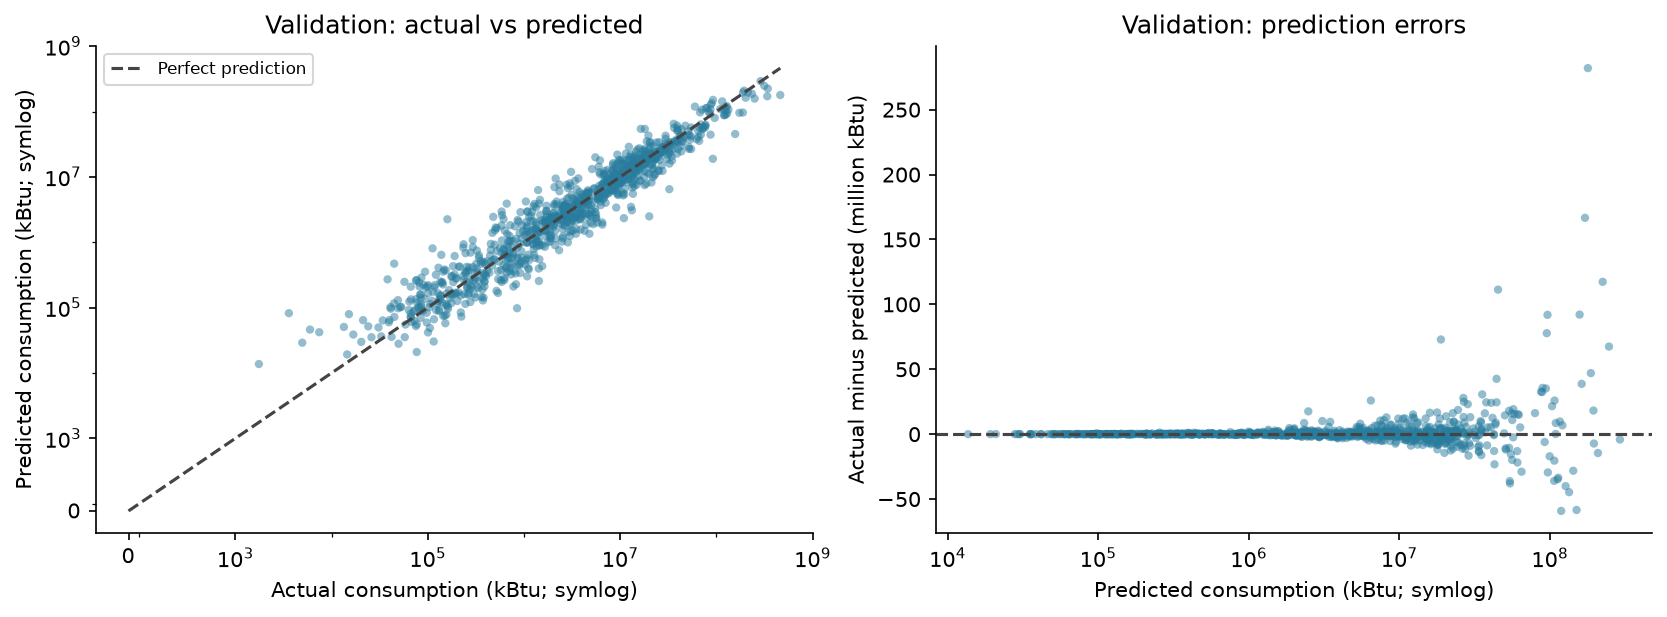

In [10]:
# Cell 24: Plot validation predictions and residuals
import matplotlib.pyplot as plt
from IPython.display import Image

plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].scatter(y_validation, best_prediction, s=16, alpha=0.5, color='#287c9e', edgecolors='none')
limit = max(y_validation.max(), best_prediction.max())
axes[0].plot([0, limit], [0, limit], '--', color='#444444', label='Perfect prediction')
axes[0].set_xscale('symlog', linthresh=1000)
axes[0].set_yscale('symlog', linthresh=1000)
axes[0].set_xticks([0, 1e3, 1e5, 1e7, 1e9])
axes[0].set_yticks([0, 1e3, 1e5, 1e7, 1e9])
axes[0].set(title='Validation: actual vs predicted', xlabel='Actual consumption (kBtu; symlog)', ylabel='Predicted consumption (kBtu; symlog)')
axes[0].legend(fontsize=8)
axes[1].scatter(best_prediction, (y_validation.to_numpy() - best_prediction) / 1e6,
                s=16, alpha=0.5, color='#287c9e', edgecolors='none')
axes[1].set_xscale('symlog', linthresh=1000)
axes[1].axhline(0, color='#444444', linestyle='--')
axes[1].set(title='Validation: prediction errors', xlabel='Predicted consumption (kBtu; symlog)', ylabel='Actual minus predicted (million kBtu)')
plot_path = results_dir / 'validation_diagnostics.png'
fig.savefig(plot_path, dpi=150, bbox_inches='tight', facecolor='white')
plt.close(fig)
display(Image(filename=str(plot_path)))

## Cell 25: Check reported and estimated targets

When metadata is available, compare reported targets with EIA estimates and
show survey-weighted errors. These checks are separate from the unweighted
selection metric. Small groups can have unstable results.

In [11]:
# Cell 26: Check target sources and survey weights
metadata_path = root / 'data/processed/metadata_validation.csv'
source_metrics = pd.DataFrame()
weighted_metrics = pd.DataFrame()
if metadata_path.exists():
    metadata = pd.read_csv(metadata_path).set_index('PUBID').reindex(validation.PUBID)
    assert metadata.index.is_unique and metadata.ZMFBTU.notna().all()
    source_names = {0: 'Reported', 1: 'EIA imputed', 2: 'Strip-center estimate'}
    rows = []
    for flag, name in source_names.items():
        mask = metadata.ZMFBTU.eq(flag).to_numpy()
        if mask.sum() >= 2:
            rows.append({'target_source': name, 'buildings': int(mask.sum()),
                         **metrics(y_validation.to_numpy()[mask], best_prediction[mask])})
    source_metrics = pd.DataFrame(rows)
    display(source_metrics.round(3))
    weights = metadata.FINALWT.to_numpy()
    assert np.isfinite(weights).all() and (weights > 0).all()
    weighted_metrics = pd.DataFrame([{
        'weighting': 'FINALWT', 'MAE_kBtu': mean_absolute_error(y_validation, best_prediction, sample_weight=weights),
        'RMSE_kBtu': np.sqrt(mean_squared_error(y_validation, best_prediction, sample_weight=weights)),
        'R2': r2_score(y_validation, best_prediction, sample_weight=weights)}])
    display(weighted_metrics.round(3))
else:
    print('Metadata not found; unweighted validation results are still available. Run preprocessing for these extra checks.')


Metadata not found; unweighted validation results are still available. Run preprocessing for these extra checks.


## Cell 27: Final test evaluation

The validation-selected model is now scored on the 954 test buildings, without
refitting or changing the data. Treat this as the final score for these settings.
Don't use the test results to tune the model further.

**Test results:** MAE 5.97 million kBtu, RMSE 22.42 million kBtu, R-squared 0.715.


In [12]:
# Cell 28: Final test evaluation
RUN_FINAL_TEST = True

if RUN_FINAL_TEST:
    test = data.loc[data['split'].eq('test')].sort_values('PUBID').copy()
    test_prediction = predict_kbtu(best_model, test[best_columns])
    final_metrics = metrics(test.MFBTU, test_prediction)
    pd.DataFrame([final_metrics]).to_csv(results_dir / 'FINAL_test_metrics.csv', index=False)
    pd.DataFrame({'PUBID': test.PUBID.to_numpy(), 'actual_MFBTU': test.MFBTU.to_numpy(),
                  'predicted_MFBTU': test_prediction}).to_csv(results_dir / 'FINAL_test_predictions.csv', index=False)
    display(pd.DataFrame([final_metrics]).round(3))
else:
    print('Final test scoring skipped.')


,MAE_kBtu,RMSE_kBtu,R2
0,5971848.004,22422646.13,0.715


## Cell 29: Step 6: Discussion

**Did the model improve?** Validation MAE fell by 19.3% compared with the simple boosting baseline, but RMSE and R-squared got worse. The selected run uses engineered inputs and a log1p fitting target. This combines several changes; it does not isolate any one effect. Log fitting reduces the influence of the largest targets, so the MAE/RMSE tradeoff is plausible. The team should keep the same primary metric when comparing models.

**Does it generalize?** The training/validation comparison and error plots help,
but test performance is weaker than validation: MAE is 5.97 million kBtu and R-squared is 0.715. Large buildings remain harder
to predict precisely, and EIA estimates affect some targets.

**What next?** We need to compare this model with Jiayi's linear regression and Alex's
neural network using identical splits and metrics. Tom can extend the feature
experiments. Avoid more tuning on the test set.

## Cell 30: Save results for the team

Saving the experiment tables, training/validation comparison, plots, and selected
train-only model. Inputs and prediction units stay the same. The model file is
optional to commit; the notebook can regenerate it. Final test metrics and predictions are saved separately.

In [13]:
# Cell 31: Export the model, tables, and plots
search.to_csv(results_dir / 'validation_search.csv', index=False)
baselines.to_csv(results_dir / 'validation_constant_references.csv', index=False)
best_by_variant.to_csv(results_dir / 'validation_best_by_variant.csv', index=False)
pd.DataFrame([best_metrics]).to_csv(results_dir / 'validation_selected_metrics.csv', index=False)
predictions = pd.DataFrame({'PUBID': validation.PUBID.to_numpy(), 'actual_MFBTU': y_validation.to_numpy(),
    'predicted_MFBTU': best_prediction, 'residual_kBtu': y_validation.to_numpy() - best_prediction})
predictions.to_csv(results_dir / 'validation_predictions.csv', index=False)
if not source_metrics.empty:
    source_metrics.to_csv(results_dir / 'validation_target_source_metrics.csv', index=False)
if not weighted_metrics.empty:
    weighted_metrics.to_csv(results_dir / 'validation_weighted_metrics.csv', index=False)

model_info = {'owner': 'Yera Smagulov', 'algorithm': 'HistGradientBoostingRegressor',
    'trial_id': str(winner.trial_id), 'feature_set': str(winner.features), 'target_fit': str(winner.target_fit),
    'parameters': settings[int(winner.setting_id) - 1], 'random_state': SEED, 'early_stopping': False,
    'feature_columns': best_columns, 'prediction_rule': 'np.maximum(model.predict(X[feature_columns]), 0)',
    'units': 'thousands of Btu (kBtu)', 'selection_metric': 'validation MAE; RMSE breaks ties',
    'validation_metrics': best_metrics, 'training_rows': len(train), 'validation_rows': len(validation),
    'training_ids_sha256': hashlib.sha256(train.PUBID.to_csv(index=False).encode()).hexdigest(),
    'validation_ids_sha256': hashlib.sha256(validation.PUBID.to_csv(index=False).encode()).hexdigest(),
    'processed_data_sha256': hashlib.sha256(data_path.read_bytes()).hexdigest(),
    'test_evaluated': bool(RUN_FINAL_TEST),
    'test_rows': len(test) if RUN_FINAL_TEST else 0,
    'test_metrics': final_metrics if RUN_FINAL_TEST else None,
    'versions': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                 'scikit-learn': sklearn.__version__, 'joblib': joblib.__version__}}
(results_dir / 'selected_model.json').write_text(json.dumps(model_info, indent=2) + '\n')
joblib.dump({'model': best_model, 'metadata': model_info}, results_dir / 'gradient_boosting_train_only.joblib')
print('Saved results and the train-only selected model to results/gradient_boosting/.')
baseline_table.to_csv(results_dir / 'baseline_boosting_metrics.csv', index=False)
comparison.to_csv(results_dir / 'model_comparison.csv', index=False)
history.to_csv(results_dir / 'learning_curves.csv', index=False)
model_info['training_metrics'] = best_train_metrics
model_info['baseline_boosting_parameters'] = baseline_params
model_info['baseline_validation_metrics'] = baseline_val_metrics
model_info['validation_MAE_improvement_over_baseline_percent'] = improvement_percent
(results_dir / 'selected_model.json').write_text(json.dumps(model_info, indent=2) + '\n')
joblib.dump({'model': best_model, 'metadata': model_info}, results_dir / 'gradient_boosting_train_only.joblib')


Saved results and the train-only selected model to results/gradient_boosting/.


['/Users/ysmagulov/Desktop/DATASCI207/results/gradient_boosting/gradient_boosting_train_only.joblib']